In [1]:
import sys
import os

sys.path.append(os.path.abspath('..'))

from quinex_application.quinex_visualisation import QuinexVisualisation
from quinex_application.metadata_visualisation import VisualisationMetadata

In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata.parquet")

# **Load Data**

In [3]:
df_paper = visualisation.load_df("../data/paper/paper_dataset.parquet")
df_paper = df_paper[df_paper["Quinex"] == True]

📂 Loaded DataFrame from '../data/paper/paper_dataset.parquet' with 81073 rows


In [4]:
metadata_df = visualisation.load_df("../data/quinex/df_quinex_metadata.parquet")
quinex_df = visualisation.load_df("../data/quinex/df_quinex.parquet")

📂 Loaded DataFrame from '../data/quinex/df_quinex_metadata.parquet' with 31633 rows
📂 Loaded DataFrame from '../data/quinex/df_quinex.parquet' with 3244165 rows


# **Analysis Metadata**

In [ ]:
mapping = {

    # --- ELSEVIER ---
    "PERGAMON-ELSEVIER SCIENCE LTD": "Elsevier",
    "ELSEVIER": "Elsevier",
    "ELSEVIER SCI LTD": "Elsevier",
    "ELSEVIER SCIENCE BV": "Elsevier",
    "ELSEVIER SCIENCE SA": "Elsevier",
    "Elsevier Ltd": "Elsevier",
    "Elsevier B.V.": "Elsevier",
    "ELSEVIER SCIENCE INC": "Elsevier",
    "Elsevier": "Elsevier",
    "Elsevier Inc.": "Elsevier",
    "ELSEVIER FRANCE-EDITIONS SCIENTIFIQUES MEDICALES ELSEVIER": "Elsevier",
    "ACADEMIC PRESS LTD- ELSEVIER SCIENCE LTD": "Elsevier",
    "ACADEMIC PRESS INC ELSEVIER SCIENCE": "Elsevier",
    "ELSEVIER - DIVISION REED ELSEVIER INDIA PVT LTD": "Elsevier",
    "ELSEVIER GMBH": "Elsevier",
    "Elsevier Inc. usjcs@elsevier.com": "Elsevier",
    'CELL PRESS': 'Elsevier',
    'Cell Press': 'Elsevier',
    'Cell Press subs@cell.com': 'Elsevier',

    # --- IEEE ---
    "Institute of Electrical and Electronics Engineers Inc.": "IEEE",
    "IEEE-INST ELECTRICAL ELECTRONICS ENGINEERS INC": "IEEE",
    "IEEE": "IEEE",
    "Institution of Engineering and Technology": "IEEE",
    "INST ENGINEERING TECHNOLOGY-IET": "IEEE",
    "IEEE Computer Society help@computer.org": "IEEE",
    "IEEE Computer Society": "IEEE",
    "IEEE COMPUTER SOC": "IEEE",
    "Institute of Electrical and Electronics Engineers": "IEEE",
    "Institution of Engineering and Technology jbristow@theiet.org": "IEEE",
    "Institution of Engineering and Technology journals@theiet.org": "IEEE",
    'INT INFORMATION & ENGINEERING TECHNOLOGY ASSOC': 'IEEE',
    'International Information and Engineering Technology Association': 'IEEE',
    'International Information and Engineering Technology Association info@iieta.org': 'IEEE',

    # --- MDPI ---
    "MDPI": "MDPI",
    "MDPI AG": "MDPI",
    "Multidisciplinary Digital Publishing Institute (MDPI)": "MDPI",
    "MDPI AG rasetti@mdpi.com Postfach Basel CH-4005": "MDPI",
    "MDPI AG indexing@mdpi.com Postfach Basel CH-4005": "MDPI",
    "MDPI AG diversity@mdpi.com": "MDPI",
    "MDPI Multidisciplinary Digital Publishing Institute rasetti@mdpi.com": "MDPI",
    "MDPI Multidisciplinary Digital Publishing Institute support@mdpi.com": "MDPI",
    "MDPI AG Postfach Basel CH-4005": "MDPI",

    # --- SPRINGER NATURE ---
    "SPRINGER": "Springer Nature",
    'Springer': 'Springer Nature',
    "Springer Science and Business Media Deutschland GmbH": "Springer Nature",
    "SPRINGER HEIDELBERG": "Springer Nature",
    "Springer Nature": "Springer Nature",
    "SPRINGERNATURE": "Springer Nature",
    "SPRINGER INTERNATIONAL PUBLISHING AG": "Springer Nature",
    "Springer International Publishing": "Springer Nature",
    "Springer Verlag service@springer.de": "Springer Nature",
    "SPRINGER SINGAPORE PTE LTD": "Springer Nature",
    "SPRINGER-VERLAG SINGAPORE PTE LTD": "Springer Nature",
    "Springer Verlag": "Springer Nature",
    "SPRINGER INT PUBL AG": "Springer Nature",
    "SPRINGER-VERLAG BERLIN": "Springer Nature",
    "Springer Science and Business Media B.V.": "Springer Nature",
    "SPRINGER WIEN": "Springer Nature",
    "SPRINGER JAPAN KK": "Springer Nature",
    'SPRINGER LONDON LTD': 'Springer Nature',
    'Springer Singapore': 'Springer Nature',
    "SPRINGER INDIA": "Springer Nature",
    "Springer Berlin Heidelberg": "Springer Nature",
    "SPRINGEROPEN": "Springer Nature",
    'Springer Science and Business Media Deutschland GmbH info@springer-sbm.com': 'Springer Nature',
    'SPRINGER INT PUBLISHING AG': 'Springer Nature',
    'SPRINGER/PLENUM PUBLISHERS': 'Springer Nature',
    "Springer Netherlands": "Springer Nature",
    "Springer New York LLC barbara.b.bertram@gsk.com": "Springer Nature",
    "Springer New York": "Springer Nature",
    "NATURE PORTFOLIO": "Springer Nature",
    "NATURE PUBLISHING GROUP": "Springer Nature",
    "Nature Research": "Springer Nature",
    

    # --- WILEY ---
    "WILEY": "Wiley",
    "wiley": "Wiley",
    "WILEY-V C H VERLAG GMBH": "Wiley",
    "Wiley Blackwell": "Wiley",
    "John Wiley and Sons Inc": "Wiley",
    "John Wiley and Sons": "Wiley",
    "John Wiley and Sons Ltd vgorayska@wiley.com Southern Gate Chichester, West Sussex PO19 8SQ": "Wiley",
    "WILEY-BLACKWELL": "Wiley",
    "WILEY PERIODICALS, INC": "Wiley",
    "WILEY-HINDAWI": "Wiley",
    "John Wiley and Sons Ltd": "Wiley",


    # --- TAYLOR & FRANCIS ---
    "TAYLOR & FRANCIS INC": "Taylor & Francis",
    "TAYLOR & FRANCIS LTD": "Taylor & Francis",
    "ROUTLEDGE JOURNALS, TAYLOR & FRANCIS LTD": "Taylor & Francis",
    "Taylor and Francis": "Taylor & Francis",
    "Taylor and Francis Ltd.": "Taylor & Francis",
    "Taylor and Francis Ltd. michael.wagreich@univie.ac.at": "Taylor & Francis",
    "Taylor and Francis Inc.": "Taylor & Francis",
    "Taylor and Francis Inc. 325 Chestnut St, Suite 800 Philadelphia PA 19106": "Taylor & Francis",
    "Routledge": "Taylor & Francis",
    "TAYLOR & FRANCIS AS": "Taylor & Francis",
    'CRC Press': 'Taylor & Francis',


    # --- IOP PUBLISHING ---
    "IOP Publishing Ltd": "IOP Publishing",
    "IOP PUBLISHING LTD": "IOP Publishing",
    "Institute of Physics": "IOP Publishing",
    "Institute of Physics Publishing helen.craven@iop.org": "IOP Publishing",
    "IOP Publishing Ltd custserv@iop.org": "IOP Publishing",


    # --- ASME ---
    "ASME": "ASME",
    "American Society of Mechanical Engineers (ASME)": "ASME",
    "American Society of Mechanical Engineers (ASME) infocentral@asme.org": "ASME",
    "ASME-AMER SOC MECHANICAL ENG": "ASME",
    "Web Portal ASME (American Society of Mechanical Engineers)": "ASME",
    "American Society of Mechanical Engineers infocentral@asme.org": "ASME",


    # --- EDP SCIENCES ---
    "EDP Sciences": "EDP Sciences",
    "E D P SCIENCES": "EDP Sciences",
    "EDP SCIENCES S A": "EDP Sciences",
    "EDP Sciences edps@edpsciences.com": "EDP Sciences",

    # --- FRONTIERS ---
    "FRONTIERS MEDIA SA": "Frontiers",
    "Frontiers Media SA": "Frontiers",
    "Frontiers Media S.A. info@frontiersin.org": "Frontiers",

    # --- AIP ---
    "AMER INST PHYSICS": "AIP",
    "AIP Publishing": "AIP",
    "American Institute of Physics Inc.": "AIP",
    "American Institute of Physics": "AIP",

    # --- AMERICAN CHEMICAL SOCIETY ---
    "AMER CHEMICAL SOC": "American Chemical Society",
    "American Chemical Society": "American Chemical Society",

    # --- SAGE ---
    "SAGE PUBLICATIONS LTD": "SAGE",
    "SAGE PUBLICATIONS INC": "SAGE",
    "SAGE Publications Inc.": "SAGE",

    # --- ROYAL SOCIETY OF CHEMISTRY ---
    "ROYAL SOC CHEMISTRY": "Royal Society of Chemistry",
    "Royal Society of Chemistry": "Royal Society of Chemistry",
    "ROYAL SOC": "Royal Society of Chemistry",

    # --- UNIVERSITY PRESS ---
    "OXFORD UNIV PRESS": "University Publisher",
    "Oxford University Press": "University Publisher",
    "OXFORD UNIV PRESS INC": "University Publisher",
    "CAMBRIDGE UNIV PRESS": "University Publisher",
    "Cambridge University Press": "University Publisher",
    "Aalborg University press": "University Publisher",
    "Aalborg University Press": "University Publisher",
}


In [ ]:
df_paper['Publisher_Group'] = df_paper['Publisher'].map(mapping).fillna(df_paper['Publisher'])

In [22]:
entity_keywords = {
    "Battery": ['battery', 'batteries', 'accumulator', "bess"],
    "H$_2$": ['hydrogen', 'H2'],
    "PV": ['PV', 'photovoltaic', 'solar panel', 'solar cell'],
    "Wind": ["wind turbine", "wind farm", "offshore", "onshore", "wind energy", "nearshore"],
    "Natural Gas": ['natural gas', 'fossil gas', 'methane'],
    "Electrolyzer": ['electrolyzer', 'electrolyser'],
    "Fuel Cell": ['fuel cell', 'FC'],
}

property_keywords = {
    "Cost": ['cost', 'LCOE', 'LCOH', 'COE', 'Capex', 'Opex'],
    "Lifetime": ["lifetime, durability", "duration", "life"],
    "Capacity": ["capacity", "power output"],
    "Efficiency": ["efficiency"],
    "Emissions": ["CO2", "emission", "GHG", "carbon footprint"],
    "Perfomance": ["performance", "yield", "output"],
}

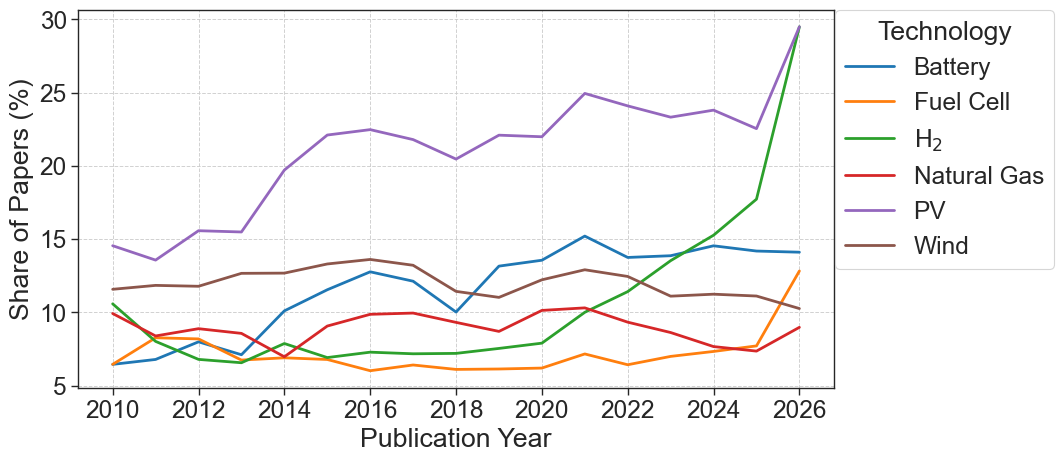

In [33]:
fig, perc = metadata.mention_trend_over_time(quinex_df, entity_keywords, "entity", figsize=(11,5), legend_position=(0.986, 1.03))
fig.savefig("../data/figures/metadata/technology_distribution.pdf")

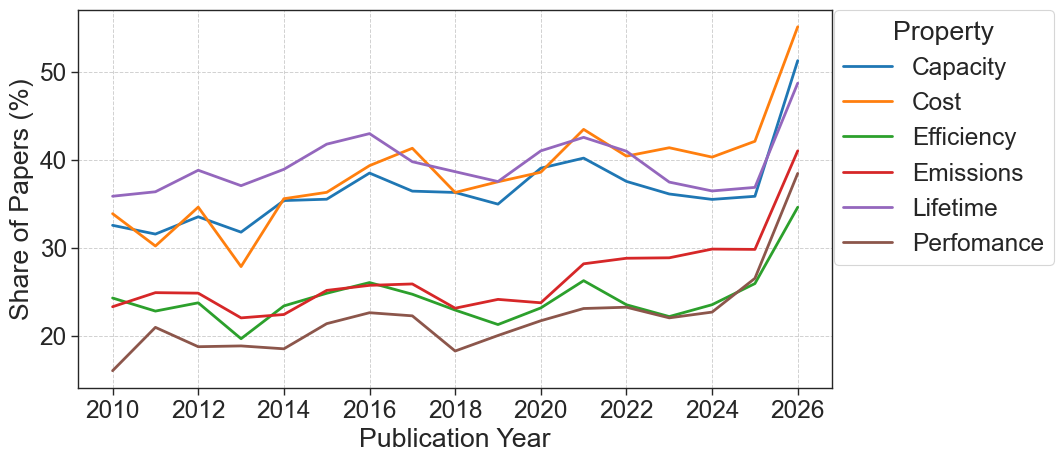

In [34]:
fig, perc = metadata.mention_trend_over_time(quinex_df, property_keywords, "property", figsize=(11,5), legend_position=(0.986, 1.03))
fig.savefig("../data/figures/metadata/property_distribution.pdf")

In [ ]:
fig = metadata.topics_distribution(metadata_df, "concepts", 12, use_percentage=True, show_other=True, figsize=(9,5))
#fig.savefig("../data/figures/concept_distribution.pdf")

In [ ]:
fig, top_counts = metadata.journal_distribution(df_paper, "Publisher_Group", "Publisher", 10, use_percentage=True, show_other=True, figsize=(9,5))
display(top_counts)
#fig.savefig("../data/figures/metadata/publisher_distribution.pdf")

Missing country info: 6091 papers (19.26 %)


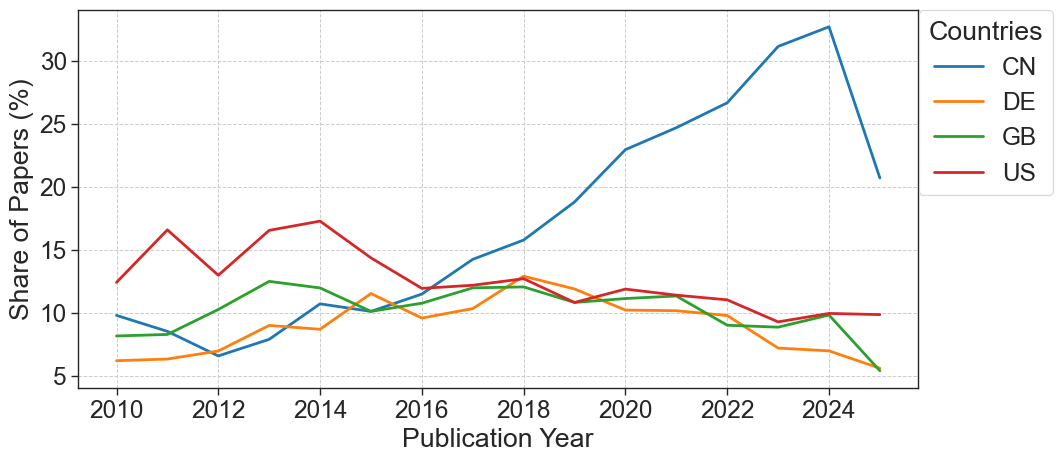

In [35]:
fig, pivot = metadata.countries_share_year(metadata_df, 4, figsize = (11, 5), legend_position = (0.986, 1.03))
fig.savefig("../data/figures/metadata/share_top_countries.pdf")